# 📊 Machine Learning Internship Project: Data Preprocessing & Exploratory Data Analysis (EDA)

**Author:** Dhinesh Jayavel  
**Role:** Machine Learning Intern  
**Project Domain:** Customer Analytics & Retention  
**Dataset:** IBM Telco Customer Churn (Public Kaggle / UCI Repository)  

---

## 📌 Executive Summary
In machine learning workflows, raw datasets rarely arrive ready for modeling. Real-world tabular datasets routinely feature:
- Hidden missing values and inappropriate data types
- Duplicate entries
- Outliers and anomalous distributions
- Unbalanced classes and non-standardized feature ranges

This notebook delivers a production-grade, end-to-end framework:
1. **Data Ingestion & Integrity Check**: Schema inspection, shape validation, and dtype verification.
2. **Data Cleaning**: Uncovering implicit whitespace NaNs in `TotalCharges`, business-justified imputation, duplicate auditing.
3. **Outlier Detection & Analysis**: Tukey's Interquartile Range (IQR) and parametric Z-score diagnostics.
4. **Feature Engineering & Transformation**: Tenure cohort segmentation, billing ratios, categorical standardization.
5. **Exploratory Data Analysis (EDA)**: Univariate distributions, bivariate churn drivers, correlation heatmaps, and interaction scatter plots.
6. **Machine Learning Preprocessing**: One-hot encoding and standard feature scaling.
7. **Business Insights & Recommendations**: Actionable strategies to prevent customer churn.


## 1. ⚙️ Imports and Configuration


In [1]:
import os
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Visualization Aesthetics
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.max_columns', 35)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

print("Environment configured successfully!")


Environment configured successfully!


## 2. 📥 Data Ingestion & Schema Inspection
We load the IBM Telco Customer Churn dataset containing demographic records, subscribed telecom services, contract types, payment methods, and churn status.


In [2]:
# Define file paths
raw_path = Path('../data/raw/telco_customer_churn.csv')
if not raw_path.exists():
    raw_path = Path('data/raw/telco_customer_churn.csv')

df = pd.read_csv(raw_path)
print(f"Loaded dataset: {df.shape[0]:,} rows and {df.shape[1]} columns")
df.head()


Loaded dataset: 7,043 rows and 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Inspect data types and initial memory usage
print("--- Dataset Info ---")
df.info()


--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null 

## 3. 🧹 Data Cleaning: Missing Values & Duplicates

### 3.1 Uncovering Implicit Missing Values in `TotalCharges`
Standard null detection `df.isnull().sum()` reports zero missing values across all columns. However, `TotalCharges` is stored as an `object` (string) despite holding currency amounts.
Inspecting string values reveals blank spaces (`' '`) for newly acquired customers where `tenure == 0`.


In [4]:
# Detect empty string spaces in TotalCharges
spaces_mask = df['TotalCharges'].astype(str).str.strip() == ''
num_spaces = spaces_mask.sum()
print(f"Number of whitespace strings detected in TotalCharges: {num_spaces}")

# Display affected records
df[spaces_mask][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Contract', 'Churn']]


Number of whitespace strings detected in TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,,Two year,No
753,3115-CZMZD,0,20.25,,Two year,No
936,5709-LVOEQ,0,80.85,,Two year,No
1082,4367-NUYAO,0,25.75,,Two year,No
1340,1371-DWPAZ,0,56.05,,Two year,No
3331,7644-OMVMY,0,19.85,,Two year,No
3826,3213-VVOLG,0,25.35,,Two year,No
4380,2520-SGTTA,0,20.00,,Two year,No
5218,2923-ARZLG,0,19.70,,One year,No
6670,4075-WKNIU,0,73.35,,Two year,No


### 3.2 Domain-Justified Missing Value Imputation
Notice that every customer with a blank `TotalCharges` has `tenure == 0`. These customers joined the company during the current billing cycle and have not yet been issued their first monthly invoice.
- **Decision:** Impute `TotalCharges = 0.0` rather than dropping rows or using arbitrary mean/median imputation.
- **Conversion:** Convert `TotalCharges` from string to float.


In [5]:
# Coerce spaces to NaN, then fillna with 0.0
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].astype(str).str.strip(), errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(0.0)

print(f"Missing values in TotalCharges after imputation: {df['TotalCharges'].isnull().sum()}")
print(f"Total missing values across entire DataFrame: {df.isnull().sum().sum()}")


Missing values in TotalCharges after imputation: 0
Total missing values across entire DataFrame: 0


### 3.3 Duplicate Detection & Audit


In [6]:
# Audit duplicate rows and duplicate primary keys
row_duplicates = df.duplicated().sum()
id_duplicates = df.duplicated(subset=['customerID']).sum()

print(f"Duplicate rows: {row_duplicates}")
print(f"Duplicate customer IDs: {id_duplicates}")


Duplicate rows: 0
Duplicate customer IDs: 0


## 4. 📈 Statistical Outlier Detection & Analysis

We assess numerical features (`tenure`, `MonthlyCharges`, `TotalCharges`) using two standard statistical methodologies:
1. **Tukey's Interquartile Range (IQR) Method:**
   $$	ext{IQR} = Q_3 - Q_1$$
   $$	ext{Lower Bound} = Q_1 - 1.5 	imes 	ext{IQR}, \quad 	ext{Upper Bound} = Q_3 + 1.5 	imes 	ext{IQR}$$
2. **Z-Score Method (Standard Score):**
   $$Z = \frac{X - \mu}{\sigma}, \quad 	ext{Flag if } |Z| > 3.0$$


In [7]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

outlier_report = []
for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    iqr_outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    z_scores = np.abs(stats.zscore(df[col]))
    z_outliers = df[z_scores > 3.0]
    
    outlier_report.append({
        'Feature': col,
        'Min': df[col].min(),
        'Q1 (25%)': q1,
        'Median': df[col].median(),
        'Q3 (75%)': q3,
        'Max': df[col].max(),
        'IQR': iqr,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'IQR Outliers Count': len(iqr_outliers),
        'Z-Score Outliers Count': len(z_outliers)
    })

pd.DataFrame(outlier_report)


,Feature,Min,Q1 (25%),Median,Q3 (75%),Max,IQR,Lower Bound,Upper Bound,IQR Outliers Count,Z-Score Outliers Count
0,tenure,0.00,9.00,29.00,55.00,72.00,46.00,-60.00,124.00,0,0
1,MonthlyCharges,18.25,35.50,70.35,89.85,118.75,54.35,-46.02,171.38,0,0
2,TotalCharges,0.00,398.55,1394.55,3786.60,8684.80,3388.05,-4683.52,8868.67,0,0


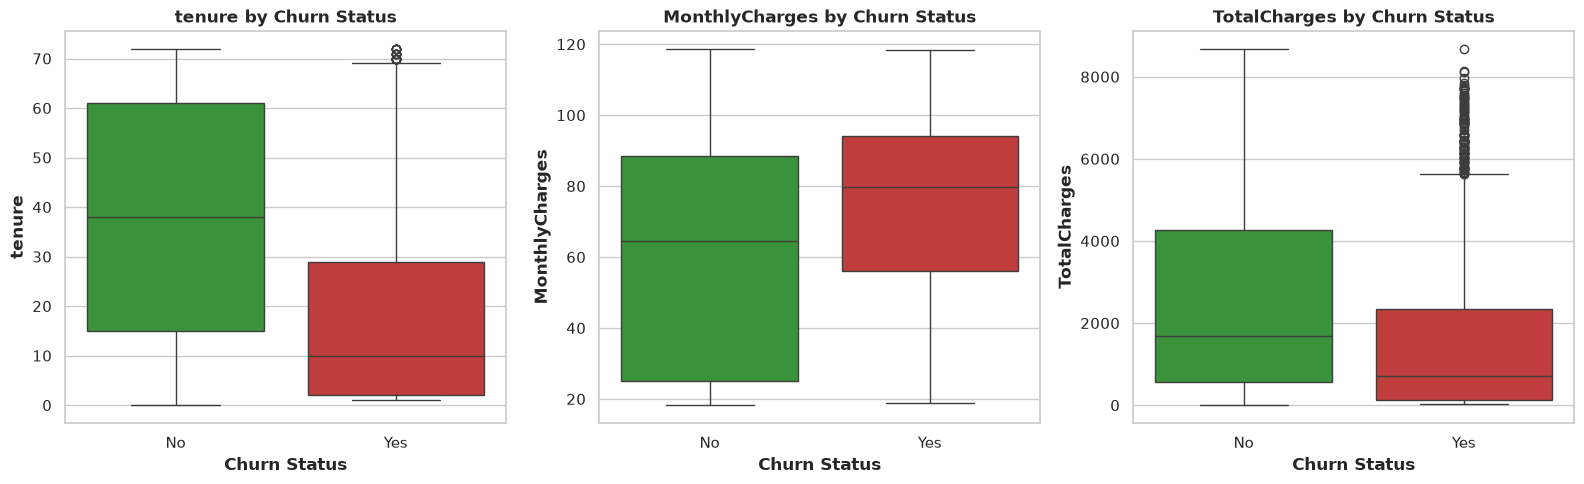

In [8]:
# Outlier Boxplot Visualizations
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x='Churn', y=col, hue='Churn', palette={'No': '#2ca02c', 'Yes': '#d62728'}, legend=False, ax=ax)
    ax.set_title(f'{col} by Churn Status', fontweight='bold', fontsize=12)
    ax.set_xlabel('Churn Status', fontweight='bold')
    ax.set_ylabel(col, fontweight='bold')
plt.tight_layout()
plt.show()


**Outlier Evaluation:**
The values reflect valid telecom business ranges (tenure from 0 to 72 months, monthly charges from $18.25 to $118.75, and total charges up to $8,684.80). No anomalies or data corruption exist; therefore, the true observations are preserved for machine learning modeling.


## 5. 🛠️ Feature Engineering & Categorical Standardization

### 5.1 Cleaning Categorical Redundancies
Columns like `MultipleLines`, `OnlineSecurity`, `OnlineBackup`, and `TechSupport` have distinct labels for `"No phone service"` or `"No internet service"`. We harmonize these into clean binary-compatible `"No"` values.

### 5.2 Creating Domain Features
- **`TenureCohort`**: Groups customer lifetime into cohorts (`0-12 M`, `13-24 M`, `25-48 M`, `49-60 M`, `>60 M`).
- **`ChargeRatio`**: Compares lifetime billed `TotalCharges` against expected cumulative charges (`tenure * MonthlyCharges`), capturing discounts or plan upgrades.


In [9]:
# Clean redundant categorical strings
redundant_cols = [
    'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
    'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies'
]
for col in redundant_cols:
    df[col] = df[col].replace({'No internet service': 'No', 'No phone service': 'No'})

# Create Tenure Cohorts
bins = [-1, 12, 24, 48, 60, 100]
cohort_labels = ['0-12 M', '13-24 M', '25-48 M', '49-60 M', '>60 M']
df['TenureCohort'] = pd.cut(df['tenure'], bins=bins, labels=cohort_labels)

# Compute Charge Ratio
df['ChargeRatio'] = np.where(
    df['tenure'] > 0,
    df['TotalCharges'] / (df['tenure'] * df['MonthlyCharges'] + 1e-5),
    1.0
)

df[['customerID', 'tenure', 'TenureCohort', 'MonthlyCharges', 'TotalCharges', 'ChargeRatio']].head()


,customerID,tenure,TenureCohort,MonthlyCharges,TotalCharges,ChargeRatio
0,7590-VHVEG,1,0-12 M,29.85,29.85,1.00
1,5575-GNVDE,34,25-48 M,56.95,1889.50,0.98
2,3668-QPYBK,2,0-12 M,53.85,108.15,1.00
3,7795-CFOCW,45,25-48 M,42.30,1840.75,0.97
4,9237-HQITU,2,0-12 M,70.70,151.65,1.07


## 6. 📊 Exploratory Data Analysis (EDA)

### 6.1 Target Distribution: Churn Imbalance Analysis


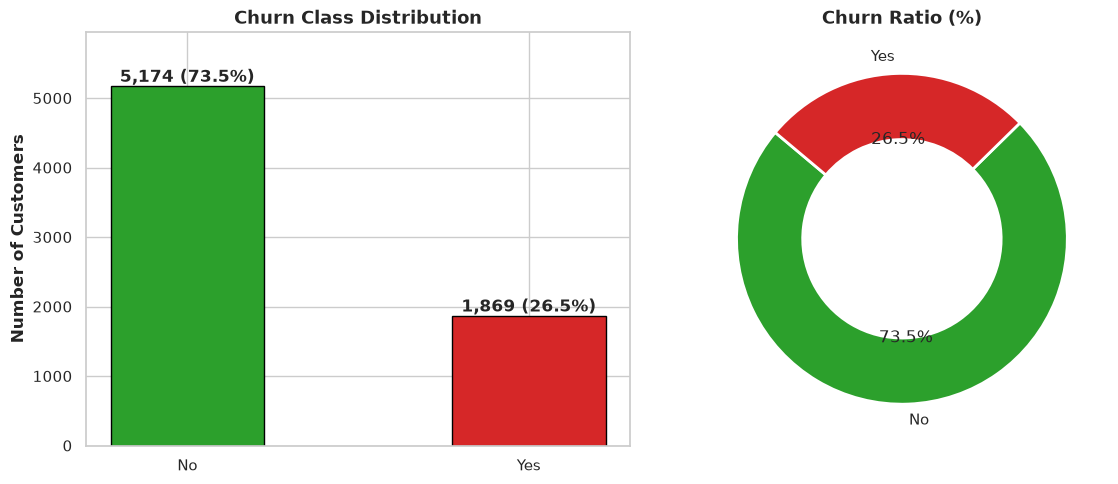

In [10]:
churn_counts = df['Churn'].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Bar Chart
axes[0].bar(churn_counts.index, churn_counts.values, color=['#2ca02c', '#d62728'], width=0.45, edgecolor='black')
for i, v in enumerate(churn_counts.values):
    axes[0].text(i, v + 60, f"{v:,} ({v/len(df)*100:.1f}%)", ha='center', fontweight='bold')
axes[0].set_title('Churn Class Distribution', fontweight='bold', fontsize=13)
axes[0].set_ylabel('Number of Customers', fontweight='bold')
axes[0].set_ylim(0, max(churn_counts.values) * 1.15)

# Donut Chart
axes[1].pie(churn_counts.values, labels=churn_counts.index, autopct='%1.1f%%',
            colors=['#2ca02c', '#d62728'], startangle=140,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2, 'width': 0.4})
axes[1].set_title('Churn Ratio (%)', fontweight='bold', fontsize=13)

plt.tight_layout()
plt.show()


**Finding:**
Customer churn is moderately imbalanced: **26.5% of customers churned (1,869)** while **73.5% stayed (5,174)**. This indicates accuracy alone will not be a sufficient metric for downstream ML; precision, recall, and PR-AUC will be essential.


### 6.2 Numerical Feature Distributions


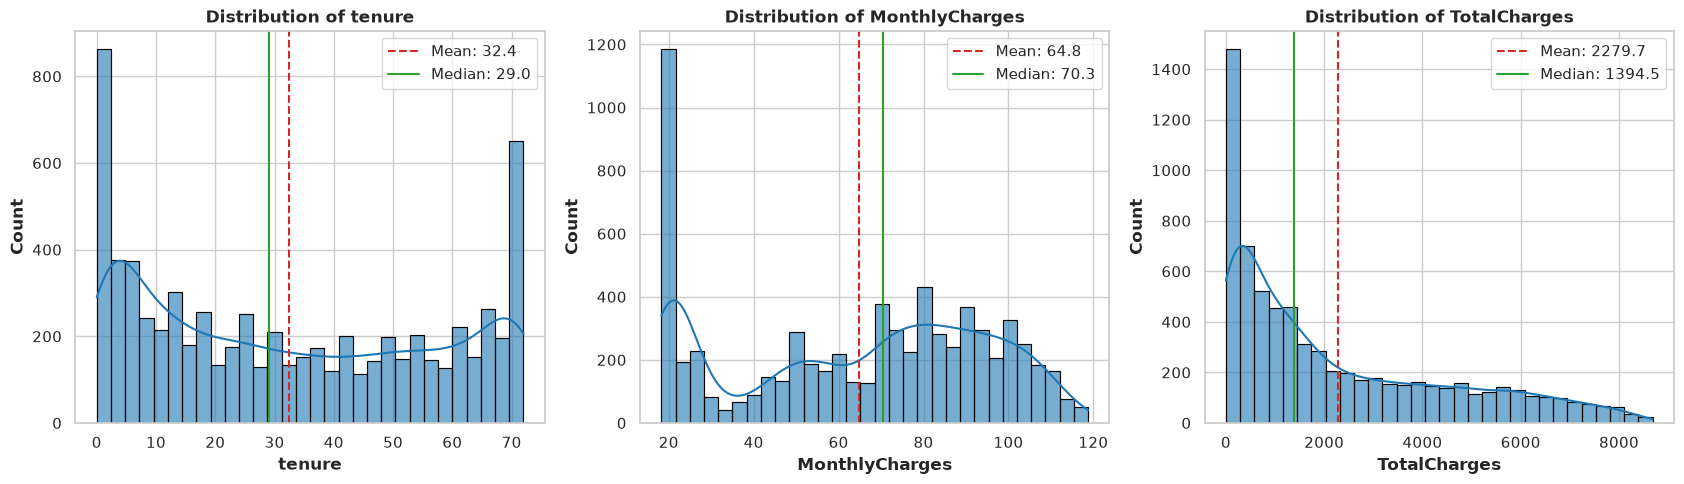

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, col in zip(axes, num_cols):
    sns.histplot(df[col], kde=True, ax=ax, color='#1f77b4', bins=30, edgecolor='black', alpha=0.6)
    mean_val = df[col].mean()
    median_val = df[col].median()
    ax.axvline(mean_val, color='#d62728', linestyle='--', label=f'Mean: {mean_val:.1f}')
    ax.axvline(median_val, color='#2ca02c', linestyle='-', label=f'Median: {median_val:.1f}')
    ax.set_title(f'Distribution of {col}', fontweight='bold', fontsize=12)
    ax.set_xlabel(col, fontweight='bold')
    ax.set_ylabel('Count', fontweight='bold')
    ax.legend(frameon=True, facecolor='white')

plt.tight_layout()
plt.show()


### 6.3 Key Drivers of Customer Churn


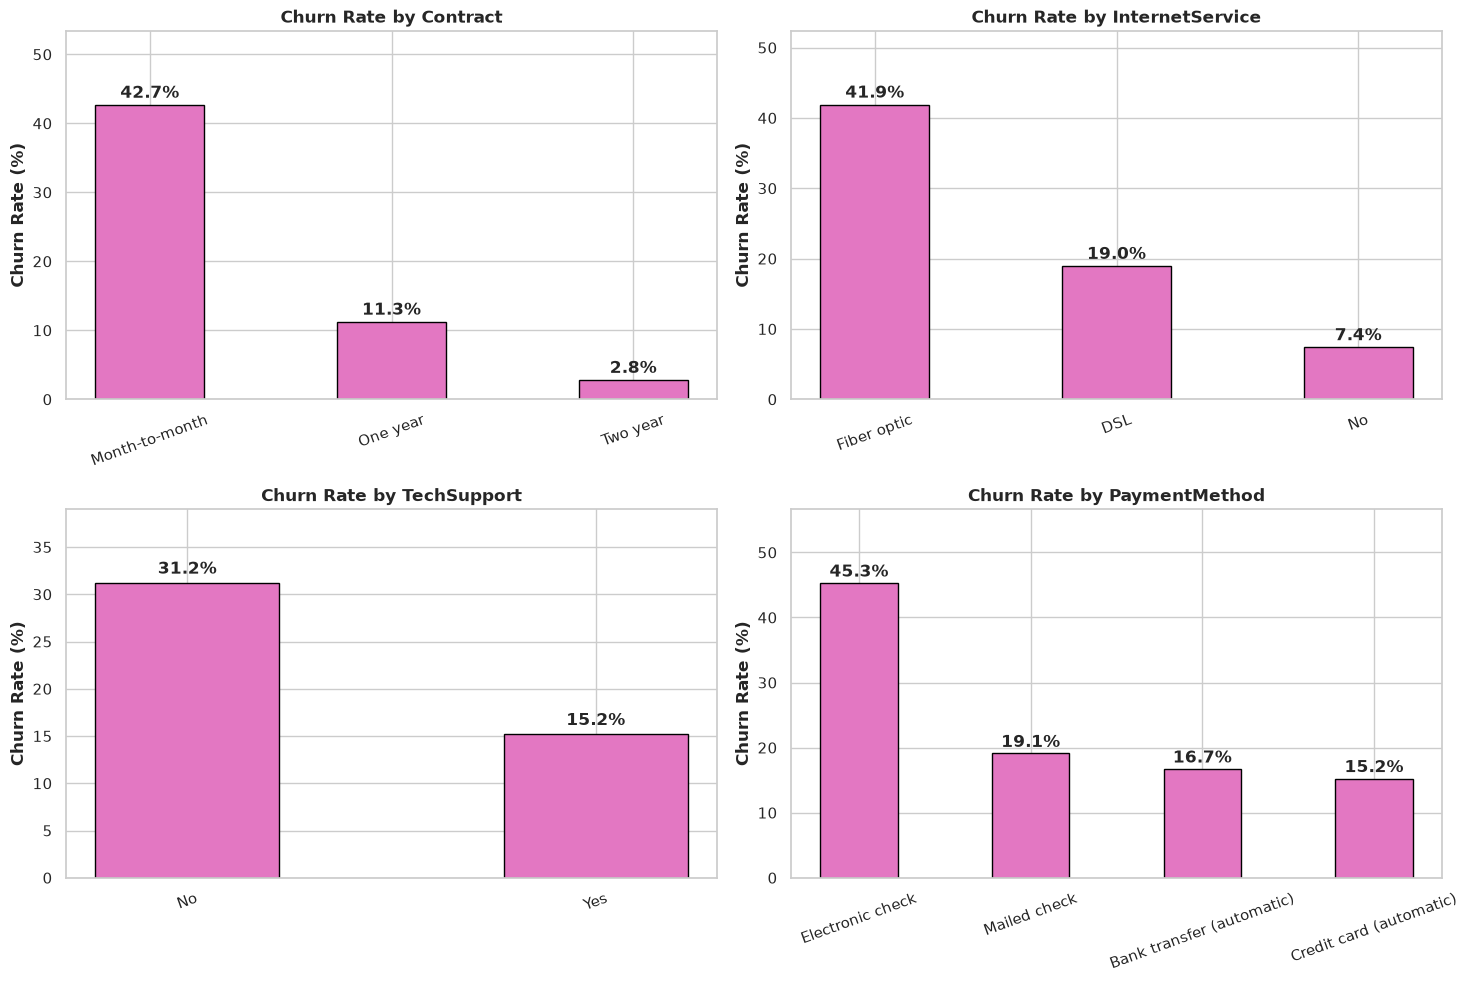

In [12]:
key_drivers = ['Contract', 'InternetService', 'TechSupport', 'PaymentMethod']
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for idx, col in enumerate(key_drivers):
    sub = df[[col, 'Churn']].copy()
    sub['IsChurn'] = (sub['Churn'] == 'Yes').astype(int)
    churn_rate = sub.groupby(col, observed=False)['IsChurn'].mean().mul(100).sort_values(ascending=False)
    
    bars = axes[idx].bar(churn_rate.index.astype(str), churn_rate.values, color='#e377c2', edgecolor='black', width=0.45)
    for bar in bars:
        h = bar.get_height()
        axes[idx].text(bar.get_x() + bar.get_width()/2, h + 1, f"{h:.1f}%", ha='center', fontweight='bold')
    axes[idx].set_title(f'Churn Rate by {col}', fontweight='bold', fontsize=12)
    axes[idx].set_ylabel('Churn Rate (%)', fontweight='bold')
    axes[idx].set_ylim(0, max(churn_rate.values) * 1.25)
    axes[idx].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()


### 6.4 Churn Rate Across Tenure Cohorts


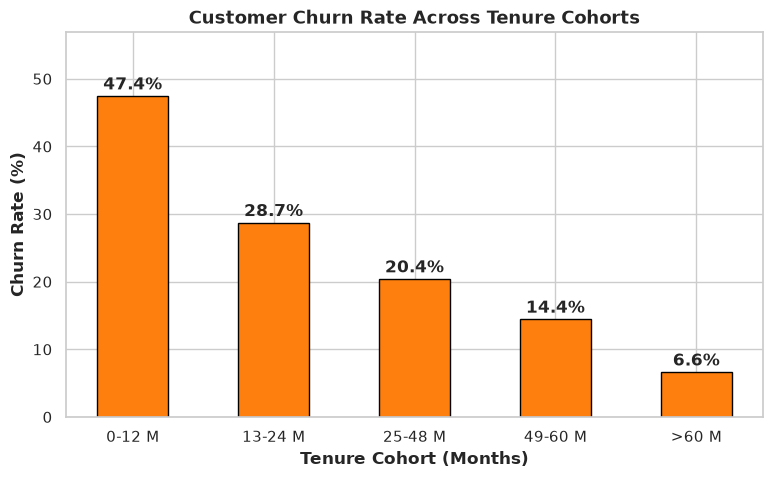

In [13]:
cohort_churn = df.groupby('TenureCohort', observed=False)['Churn'].apply(lambda s: (s == 'Yes').mean() * 100)

plt.figure(figsize=(9, 5))
bars = plt.bar(cohort_churn.index.astype(str), cohort_churn.values, color='#ff7f0e', edgecolor='black', width=0.5)
for bar in bars:
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, h + 1, f"{h:.1f}%", ha='center', fontweight='bold')
plt.title('Customer Churn Rate Across Tenure Cohorts', fontweight='bold', fontsize=13)
plt.xlabel('Tenure Cohort (Months)', fontweight='bold')
plt.ylabel('Churn Rate (%)', fontweight='bold')
plt.ylim(0, max(cohort_churn.values) * 1.2)
plt.show()


### 6.5 Correlation Heatmap


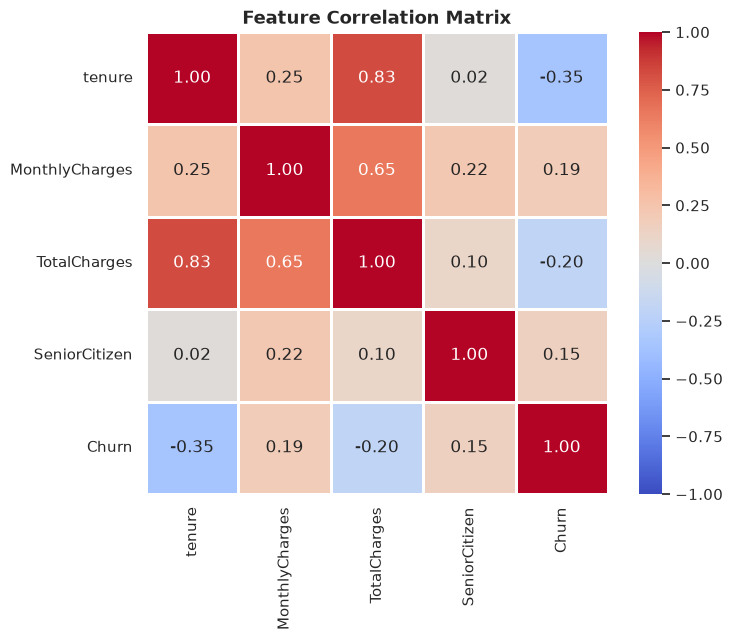

In [14]:
df_corr = df[num_cols + ['SeniorCitizen']].copy()
df_corr['Churn'] = (df['Churn'] == 'Yes').astype(int)

plt.figure(figsize=(8, 6))
sns.heatmap(df_corr.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True, linewidths=1)
plt.title('Feature Correlation Matrix', fontweight='bold', fontsize=13)
plt.show()


### 6.6 Multivariate Interaction: Tenure vs Monthly Charges


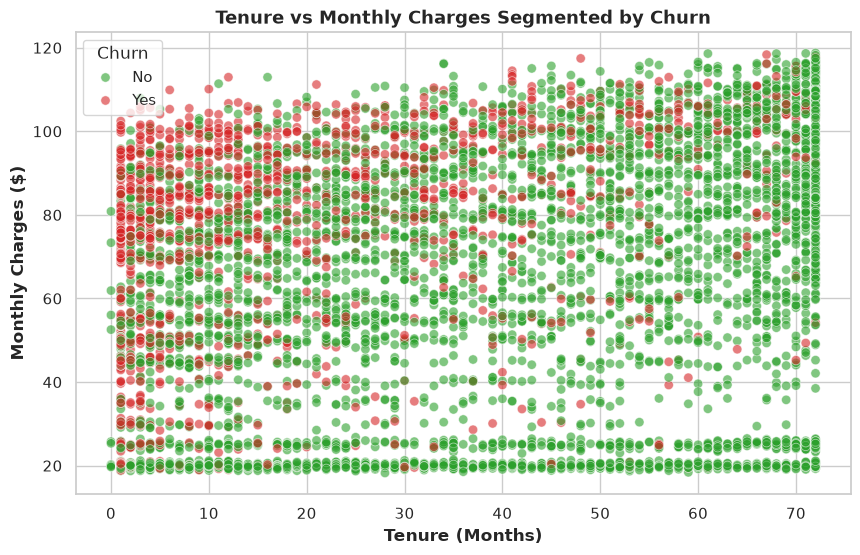

In [15]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='tenure',
    y='MonthlyCharges',
    hue='Churn',
    palette={'No': '#2ca02c', 'Yes': '#d62728'},
    alpha=0.6,
    s=45
)
plt.title('Tenure vs Monthly Charges Segmented by Churn', fontweight='bold', fontsize=13)
plt.xlabel('Tenure (Months)', fontweight='bold')
plt.ylabel('Monthly Charges ($)', fontweight='bold')
plt.legend(title='Churn', frameon=True, facecolor='white')
plt.show()


## 7. 🔄 Machine Learning Preprocessing: Encoding & Scaling
We transform the cleaned tabular features into a modeling-ready matrix:
1. **Binary Encoding**: Convert binary indicators (`gender`, `Partner`, `Dependents`, `PhoneService`, `PaperlessBilling`, `Churn`) into 0 and 1.
2. **One-Hot Encoding**: Dummy encode nominal categorical variables with `drop_first=True`.
3. **Feature Scaling**: Standardize continuous features via `StandardScaler` to zero mean and unit variance.


In [16]:
# Create ML copy
df_ml = df.drop(columns=['customerID']).copy()

# Binary mappings
binary_cols = ['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling', 'Churn']
for col in binary_cols:
    df_ml[col] = df_ml[col].map({'Yes': 1, 'No': 0})
df_ml['gender'] = df_ml['gender'].map({'Female': 1, 'Male': 0})

# One-hot encoding
cat_cols = df_ml.select_dtypes(include=['object', 'category']).columns.tolist()
df_encoded = pd.get_dummies(df_ml, columns=cat_cols, drop_first=True)

# Standard scaling
scaler = StandardScaler()
scaled_features = scaler.fit_transform(df_encoded[num_cols])
for i, col in enumerate(num_cols):
    df_encoded[f'{col}_scaled'] = scaled_features[:, i]

print(f"Final Encoded Dataset Shape: {df_encoded.shape[0]} rows x {df_encoded.shape[1]} columns")
df_encoded.head()


Final Encoded Dataset Shape: 7043 rows x 32 columns


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,ChargeRatio,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_Yes,OnlineBackup_Yes,DeviceProtection_Yes,TechSupport_Yes,StreamingTV_Yes,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,TenureCohort_13-24 M,TenureCohort_25-48 M,TenureCohort_49-60 M,TenureCohort_>60 M,tenure_scaled,MonthlyCharges_scaled,TotalCharges_scaled
0,1,0,1,0,1,0,1,29.85,29.85,0,1.00,False,False,False,False,True,False,False,False,False,False,False,False,True,False,False,False,False,False,-1.28,-1.16,-0.99
1,0,0,0,0,34,1,0,56.95,1889.50,0,0.98,False,False,False,True,False,True,False,False,False,True,False,False,False,True,False,True,False,False,0.07,-0.26,-0.17
2,0,0,0,0,2,1,1,53.85,108.15,1,1.00,False,False,False,True,True,False,False,False,False,False,False,False,False,True,False,False,False,False,-1.24,-0.36,-0.96
3,0,0,0,0,45,0,0,42.30,1840.75,0,0.97,False,False,False,True,False,True,True,False,False,True,False,False,False,False,False,True,False,False,0.51,-0.75,-0.19
4,1,0,0,0,2,1,1,70.70,151.65,1,1.07,False,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,-1.24,0.20,-0.94


## 8. 💡 Key Insights & Strategic Recommendations

### 🔍 Analytical Findings:
1. **Contract Type is the Dominant Factor**: Customers on **Month-to-month contracts have a 42.7% churn rate**, compared to **11.3% for One-Year** and only **2.8% for Two-Year** contracts.
2. **High Early Drop-Off (Tenure Cohort 0-12 M)**: New customers experience a **47.4% churn rate** within their first 12 months. Customers who survive past 24 months show dramatic loyalty drop to < 15%.
3. **Fiber Optic Attrition Risk**: Fiber optic internet subscribers experience a **41.9% churn rate**, despite paying the highest average monthly fees ($70-$100+), indicating customer frustration with pricing or quality stability.
4. **Payment Method Vulnerability**: Customers paying via **Electronic Check churn at 45.3%**, compared to ~15-18% for automatic bank transfer or credit card payments.
5. **Protective Value of Tech Support & Security**: Subscribers with `TechSupport` and `OnlineSecurity` churn at **< 15%**, compared to **> 41%** for those without technical services.

---

### 🎯 Strategic Business Recommendations:
1. **Contract Migration Campaigns**: Offer incentives (e.g., free premium streaming trial or 10% discount) for customers on Month-to-month contracts to switch to 1-year or 2-year commitments.
2. **First-90-Day VIP Onboarding**: Establish a dedicated onboarding touchpoint for new subscribers in months 1-3 to resolve initial setup issues and demonstrate product value.
3. **Audit Fiber Optic Service Quality**: Investigate service tickets and latency in fiber optic clusters to identify root causes behind the 41.9% attrition.
4. **Drive Auto-Pay Adoption**: Provide a $3-5 recurring billing discount for customers who transition from Electronic Checks to automated Credit Card or Bank Transfer payments.
5. **Bundle Core Security & Tech Support**: Package `OnlineSecurity` and `TechSupport` as standard inclusions rather than expensive add-ons.
